In [ ]:
!uv pip install Pillow numpy matplotlib scipy scikit-image

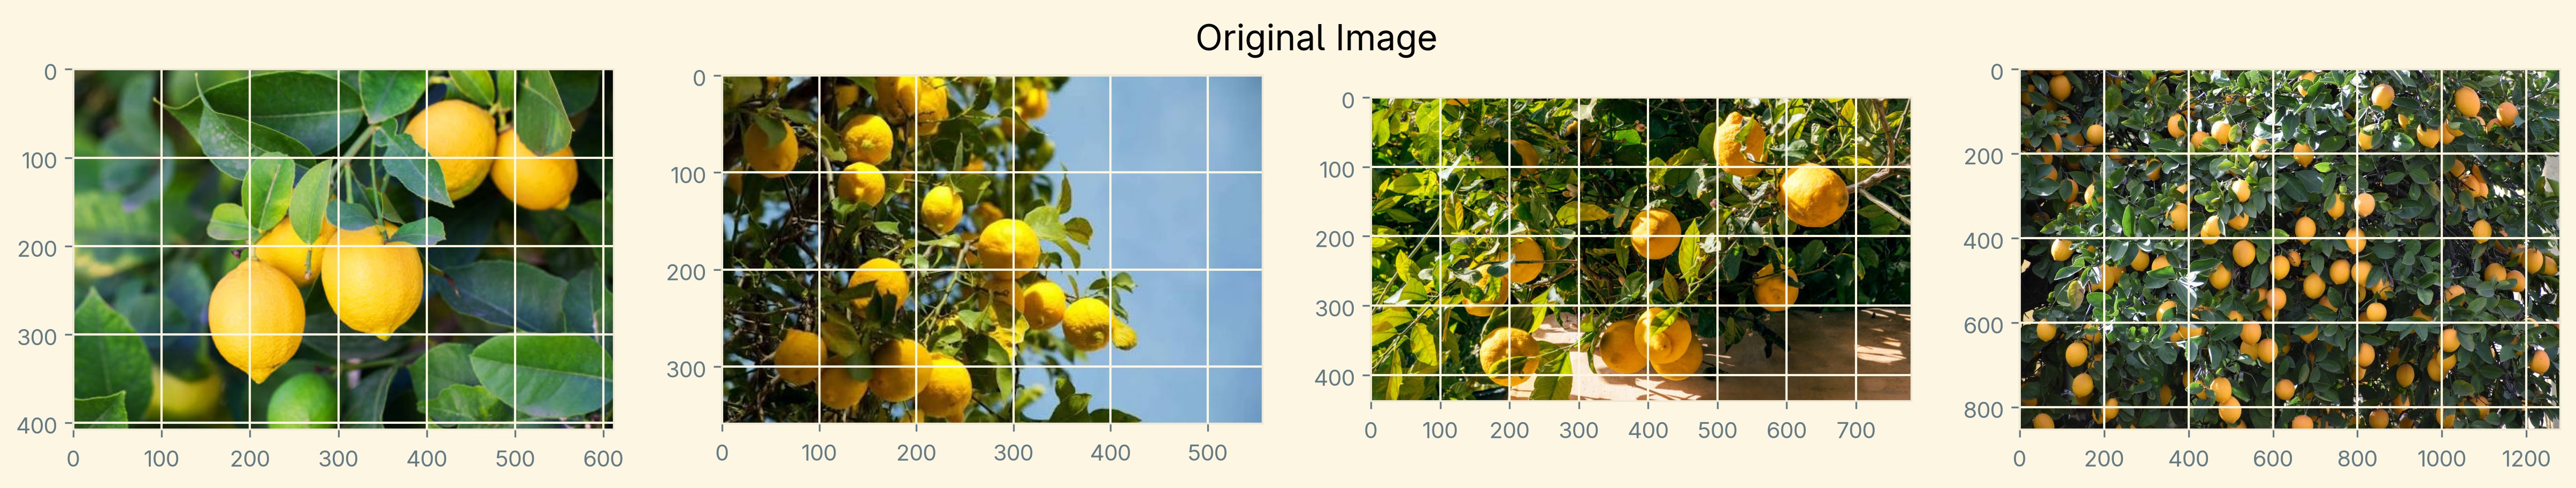

In [77]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.style import available
import numpy as np
from scipy import ndimage

plt.rcParams["font.family"] = "Adwaita Sans"
COLOR = '#000'
mpl.rcParams['text.color'] = COLOR
mpl.rcParams['axes.labelcolor'] = COLOR
mpl.rcParams['xtick.color'] = COLOR
mpl.rcParams['ytick.color'] = COLOR


images = {
  "lemon1": Image.open("./lemon_tree1.jpg"),
  "lemon2": Image.open("./lemon_tree2.jpg"),
  "lemon3": Image.open("./lemon_tree3.jpg"),
  "lemon4": Image.open("./lemon_tree4.jpg"),
}

plt.style.use("Solarize_Light2")
plt.figure(figsize=(20, 3), dpi=300)
plt.title(f'Original Image')
plt.axis("off")

for ((name, img), i) in zip(images.items(), range(1, 5)):
    plt.subplot(1, 4, i)
    plt.imshow(img)

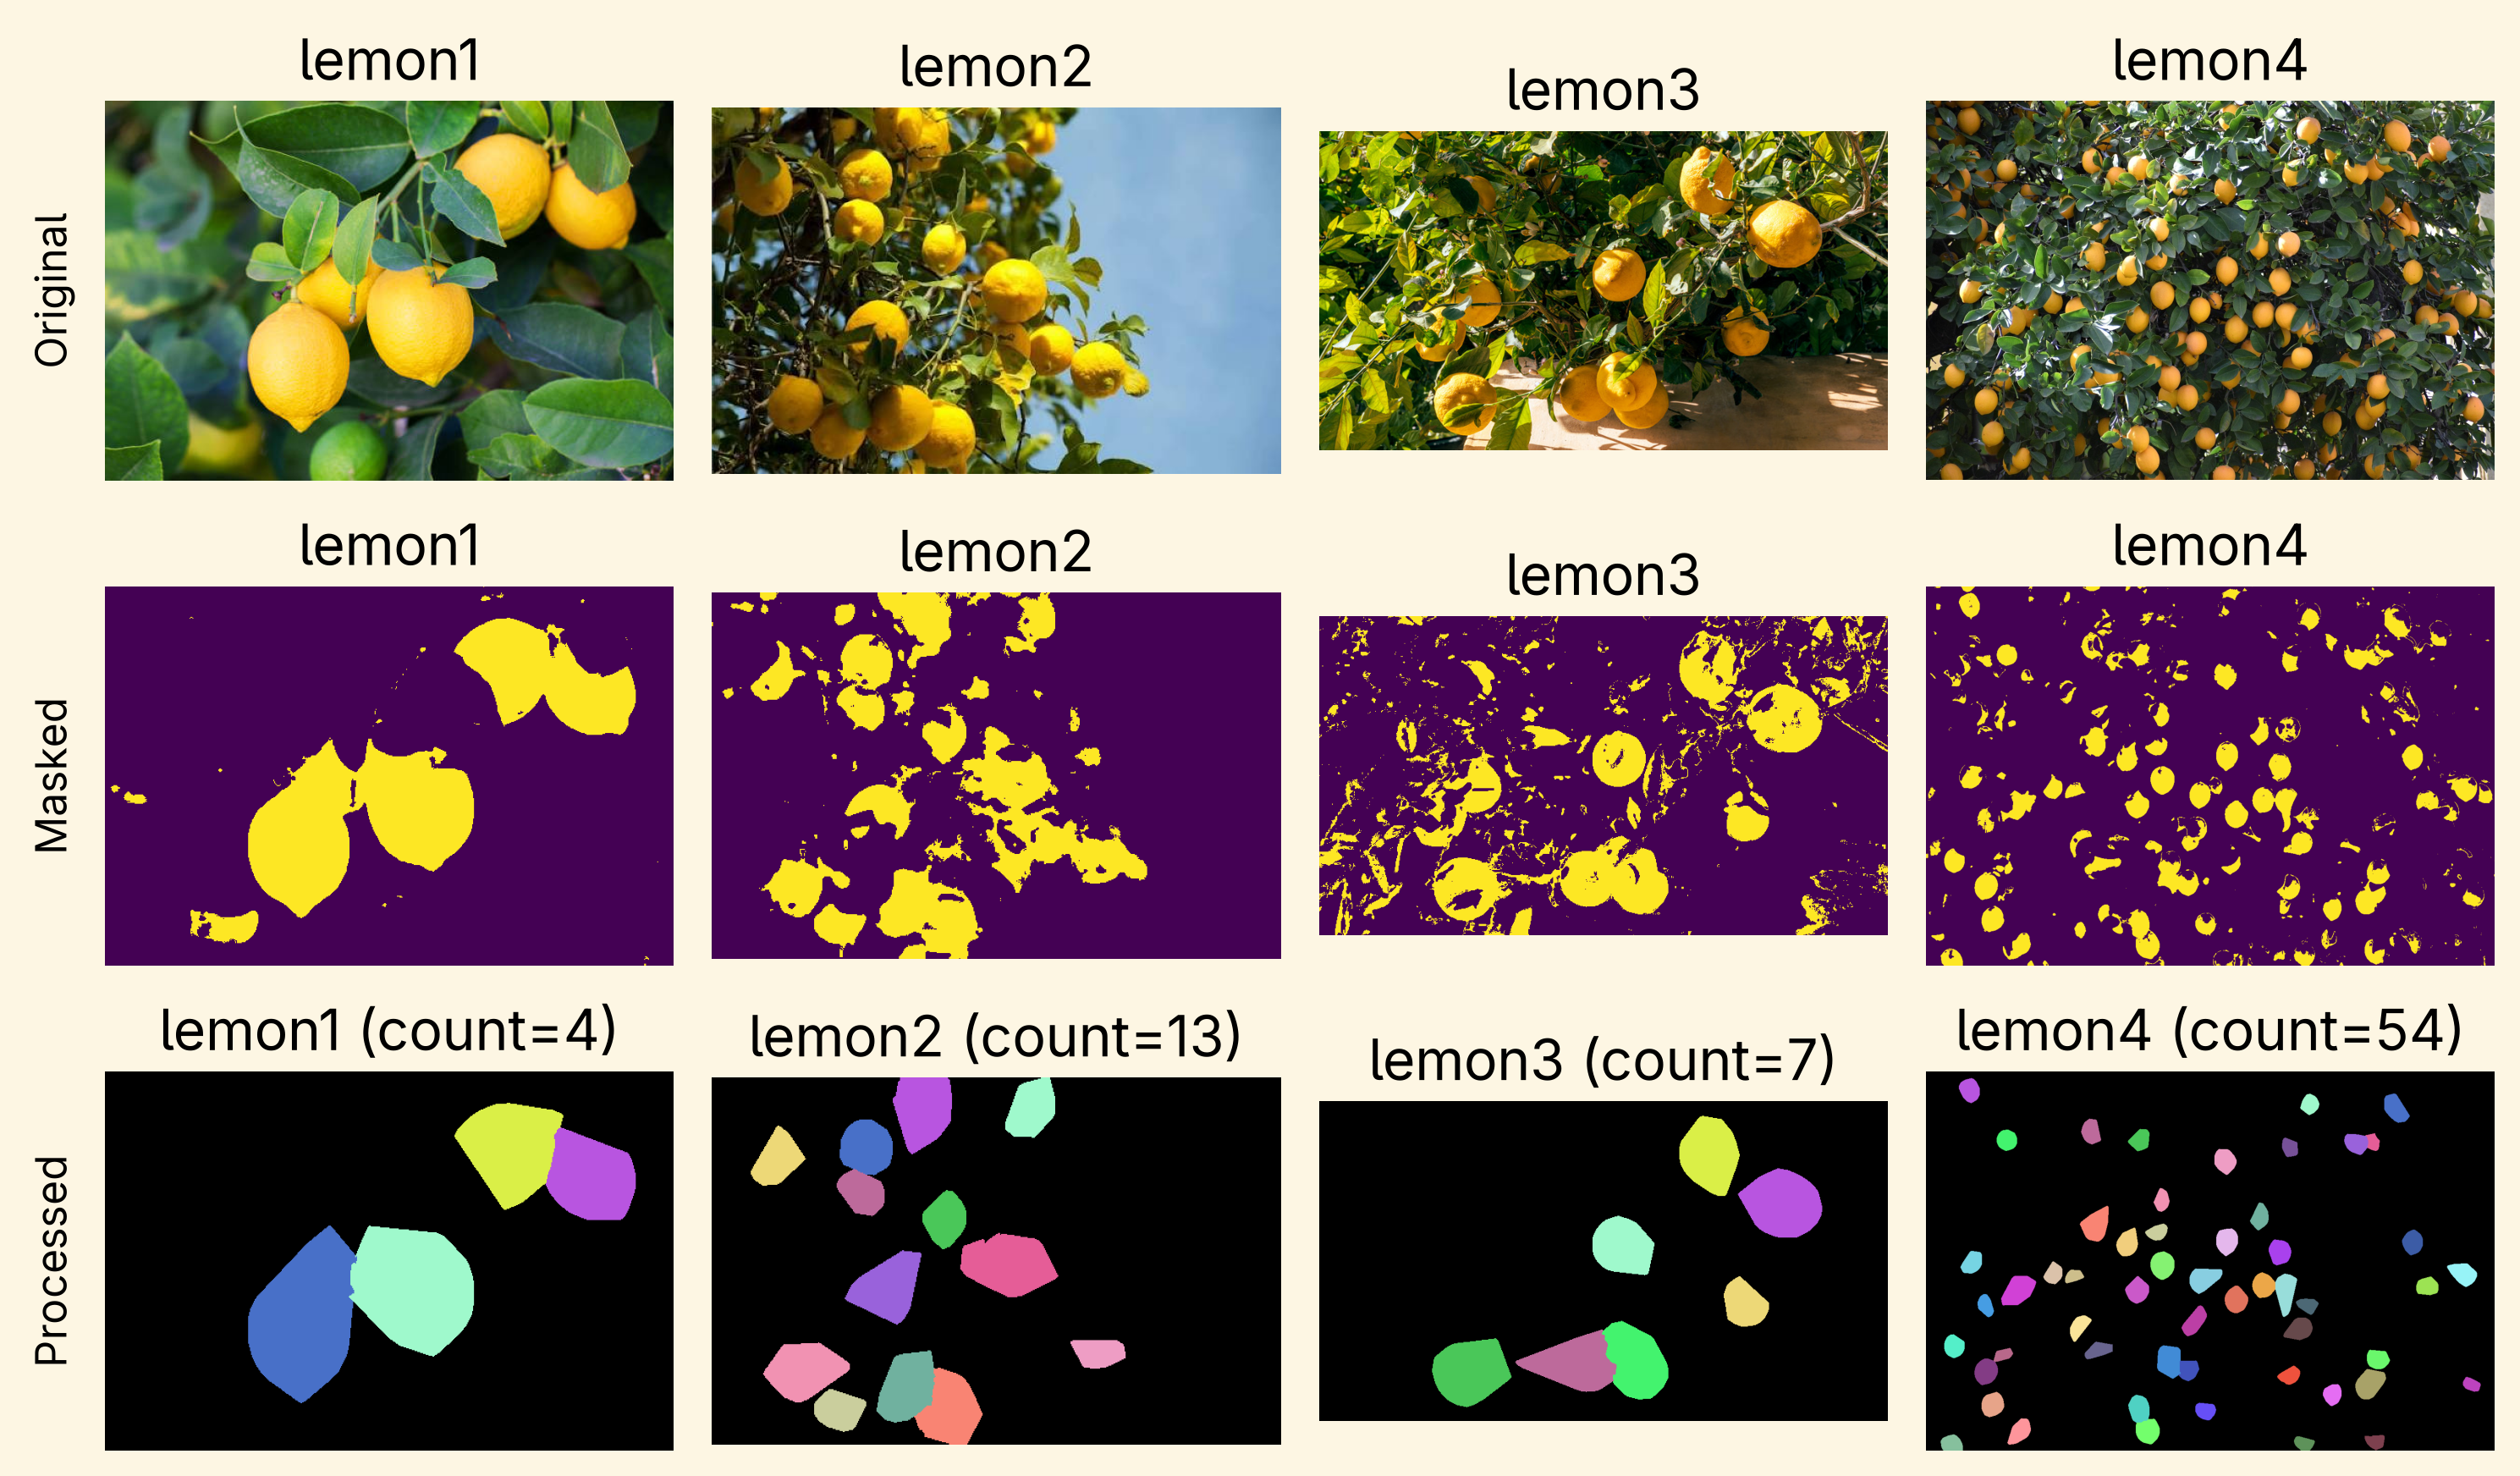

In [ ]:
from PIL import ImageDraw
import numpy as np
from PIL import Image, ImageFilter
import heapq
from collections import deque

import numpy as np
from PIL import Image, ImageFilter

N4 = ((-1, 0), (1, 0), (0, -1), (0, 1))
N8 = N4 + ((-1, -1), (-1, 1), (1, -1), (1, 1))


def disk(r: int) -> np.ndarray:
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x * x + y * y <= r * r


def _shifts(se: np.ndarray):
    c = se.shape[0] // 2
    return [(dy - c, dx - c) for dy, dx in zip(*np.nonzero(se))]


def _shifted(a: np.ndarray, dy: int, dx: int, fill):
    """a shifted by (dy, dx), padded with `fill`."""
    out = np.full_like(a, fill)
    h, w = a.shape
    out[max(dy, 0):h + min(dy, 0), max(dx, 0):w + min(dx, 0)] = \
        a[max(-dy, 0):h + min(-dy, 0), max(-dx, 0):w + min(-dx, 0)]
    return out


def min_filter(a, se):   # Ch3 min filter == erosion on a binary mask
    out = np.ones_like(a) if a.dtype == bool else np.full_like(a, a.max())
    for dy, dx in _shifts(se):
        out = np.minimum(out, _shifted(
            a, dy, dx, a.max() if a.dtype != bool else True))
    return out


def max_filter(a, se):   # Ch3 max filter == dilation on a binary mask
    out = np.zeros_like(a)
    for dy, dx in _shifts(se):
        out = np.maximum(out, _shifted(a, dy, dx, 0))
    return out


def label(mask: np.ndarray, neighbours=N4):
    """Connected-component labeling by BFS (Ch2). Returns (labels, n)."""
    h, w = mask.shape
    lab = np.zeros((h, w), np.int32)
    m = mask.tolist()          # python lists are much faster to index than numpy
    L = lab.tolist()
    n = 0
    for y in range(h):
        row = m[y]
        for x in range(w):
            if row[x] and not L[y][x]:
                n += 1
                L[y][x] = n
                q = deque([(y, x)])
                while q:
                    cy, cx = q.popleft()
                    for dy, dx in neighbours:
                        ny, nx = cy + dy, cx + dx
                        if 0 <= ny < h and 0 <= nx < w and m[ny][nx] and not L[ny][nx]:
                            L[ny][nx] = n
                            q.append((ny, nx))
    return np.array(L, np.int32), n


def fill_holes(mask):
    """Background regions that don't touch the border are holes."""
    bg, _ = label(~mask)
    border = np.unique(np.concatenate([bg[0], bg[-1], bg[:, 0], bg[:, -1]]))
    return mask | (~np.isin(bg, border))


def distance(mask):
    """Distance to background = how many erosions a pixel survives.
    Alternating D4 (cross) and D8 (square) steps (Ch2) gives an octagon,
    much rounder than either alone, so each lemon gets one clean peak."""
    d = np.zeros(mask.shape, np.float32)
    cur = mask.copy()
    cross, square = disk(1), np.ones((3, 3), bool)
    i = 0
    while cur.any():
        d += cur
        cur = min_filter(cur, cross if i % 2 == 0 else square)
        i += 1
    return d


def mean_filter(a, k=5):
    """Box smoothing (Ch3) via a summed-area table."""
    p = k // 2
    a = np.pad(a.astype(np.float32), p, mode="edge")
    s = np.pad(a.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    return (s[k:, k:] - s[:-k, k:] - s[k:, :-k] + s[:-k, :-k]) / (k * k)


def watershed(dist, markers, mask):
    """Priority flood from markers; highest distance first, so regions meet at the necks."""
    h, w = mask.shape
    seg = markers.tolist()
    D = dist.tolist()
    M = mask.tolist()
    heap = []
    for y, x in zip(*np.nonzero(markers)):
        heapq.heappush(heap, (-D[y][x], int(y), int(x)))
    while heap:
        _, y, x = heapq.heappop(heap)
        lbl = seg[y][x]
        for dy, dx in N4:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and M[ny][nx] and not seg[ny][nx]:
                seg[ny][nx] = lbl
                heapq.heappush(heap, (-D[ny][nx], ny, nx))
    return np.array(seg, np.int32)


def colorize(seg):
    rng = np.random.default_rng(0)
    palette = rng.integers(60, 256, (seg.max() + 1, 3), dtype=np.uint8)
    palette[0] = 0
    return palette[seg]


def region_shape(seg):
    """Per-label area, elongation and fill, from image moments."""
    ys, xs = np.nonzero(seg)
    l = seg[ys, xs]
    n = np.bincount(l, minlength=seg.max() + 1).astype(float)
    n[n == 0] = np.nan
    my, mx = np.bincount(l, ys, len(n)) / n, np.bincount(l, xs, len(n)) / n
    dy, dx = ys - my[l], xs - mx[l]
    syy = np.bincount(l, dy * dy, len(n)) / n
    sxx = np.bincount(l, dx * dx, len(n)) / n
    sxy = np.bincount(l, dx * dy, len(n)) / n
    tr, det = syy + sxx, syy * sxx - sxy ** 2
    root = np.sqrt(np.maximum(tr ** 2 / 4 - det, 0))
    l1, l2 = tr / 2 + root, np.maximum(tr / 2 - root, 1e-6)
    # 1 = round, large = stick-like
    elong = np.sqrt(l1 / l2)
    # ≈1 solid blob, low = ragged/branchy
    fill = n / (4 * np.pi * np.sqrt(l1 * l2))
    return n, elong, fill


def shape_filter(seg, max_elong=2.5, min_fill=0.55):
    _, elong, fill = region_shape(seg)
    good = np.nan_to_num((elong <= max_elong) &
                         (fill >= min_fill)).astype(bool)
    good[0] = False
    return np.where(good[seg], seg, 0)


def sobel(gray):
    """Sobel gradient magnitude (Ch7)."""
    g = gray.astype(np.float32)
    def s(dy, dx): return _shifted(g, dy, dx, 0)
    gx = (s(-1, -1) + 2*s(0, -1) + s(1, -1)) - (s(-1, 1) + 2*s(0, 1) + s(1, 1))
    gy = (s(-1, -1) + 2*s(-1, 0) + s(-1, 1)) - (s(1, -1) + 2*s(1, 0) + s(1, 1))
    mag = np.hypot(gx, gy)
    mag[[0, -1], :] = 0
    mag[:, [0, -1]] = 0
    return mag


def watershed_cost(cost, markers, mask):
    """Grow into the cheapest pixel first; regions meet where cost is high (edges/necks)."""
    h, w = mask.shape
    seg, C, M = markers.tolist(), cost.tolist(), mask.tolist()
    heap = [(C[y][x], int(y), int(x)) for y, x in zip(*np.nonzero(markers))]
    heapq.heapify(heap)
    while heap:
        _, y, x = heapq.heappop(heap)
        lbl = seg[y][x]
        for dy, dx in N4:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and M[ny][nx] and not seg[ny][nx]:
                seg[ny][nx] = lbl
                heapq.heappush(heap, (C[ny][nx], ny, nx))
    return np.array(seg, np.int32)


def _hull(points):
    """Andrew's monotone-chain convex hull; points = [(x, y), ...]."""
    pts = sorted(set(points))
    if len(pts) < 3:
        return pts

    def cross(o, a, b): return (a[0]-o[0]) * \
        (b[1]-o[1]) - (a[1]-o[1])*(b[0]-o[0])
    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]


def convex_outline(seg):
    """Fill each lemon's convex hull, never stealing another lemon's pixels."""
    out = seg.copy()
    ys, xs = np.nonzero(seg)
    l = seg[ys, xs]
    o = np.argsort(l, kind="stable")
    ys, xs, l = ys[o], xs[o], l[o]
    starts = np.r_[0, np.nonzero(np.diff(l))[0] + 1, len(l)]
    h, w = seg.shape
    for a, b in zip(starts[:-1], starts[1:]):
        ry, rx, lbl = ys[a:b], xs[a:b], int(l[a])
        pts = []
        for y in np.unique(ry):                 # only row extremes matter for a hull
            row = rx[ry == y]
            pts += [(int(row.min()), int(y)), (int(row.max()), int(y))]
        hull = _hull(pts)
        if len(hull) < 3:
            continue
        canvas = Image.new("1", (w, h), 0)
        ImageDraw.Draw(canvas).polygon(hull, fill=1, outline=1)
        out[np.asarray(canvas) & (out == 0)] = lbl
    return out


def count_lemon(image: Image.Image, min_area=100, edge_weight=1.5, hue_min=23, hue_max=40, sat_min=90, sat_max=100, val_min=99, val_max=100):
    # region 1
    # 1) Median filter (Ch3) then colour slicing in HSV (Ch6)
    image = image.convert("RGB").filter(ImageFilter.MedianFilter(5))
    hsv = np.asarray(image.convert("HSV"))
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    mask = ((hue >= hue_min) & (hue <= hue_max)) & (sat >= sat_min) & (sat <= sat_max) & (val >= val_min) & (val <= val_max)
    # endregion 1

    # region 2
    # 2) Clean: opening/closing via min/max filters (Ch3), holes, region rejection (Ch7)
    se = disk(max(1, round(min(mask.shape) * 0.004)))
    clean = max_filter(min_filter(mask, se), se)          # opening
    clean = min_filter(max_filter(clean, se), se)         # closing
    clean = fill_holes(clean)
    blobs, n = label(clean)
    areas = np.bincount(blobs.ravel())
    clean &= areas[blobs] >= min_area
    blobs[~clean] = 0
    if not clean.any():
        return 0, mask, np.zeros((*mask.shape, 3), np.uint8)

    # endregion 2
    # region 3
    # 3) Seeds = local maxima of the distance map (max filter, Ch3)
    dist = mean_filter(distance(clean), 5) * clean   # smooth away ripples
    radii = np.zeros(n + 1, np.float32)
    np.maximum.at(radii, blobs.ravel(), dist.ravel())
    r_typ = float(np.median(radii[radii > 0]))
    win = disk(max(2, int(0.7 * r_typ)))
    peaks = (dist >= max_filter(dist, win) -
             1e-6) & (dist >= 0.4 * r_typ) & clean
    # merge plateau pixels into one seed
    markers, _ = label(peaks, N8)
    # endregion 3
    # region 4
    # 4) Edge-guided watershed: Sobel on brightness marks the crease between lemons
    grad = mean_filter(sobel(val), 3)
    grad = np.clip(grad / (np.percentile(grad[clean], 95) + 1e-6), 0, 1)
    # low in lemon centers, high on edges
    cost = -dist / r_typ + edge_weight * grad
    seg = watershed_cost(cost, markers, clean)

    seg = shape_filter(seg)        # judge shape on the REAL pixels first...
    seg = convex_outline(seg)      # ...then tidy the survivors' outlines
    areas = np.bincount(seg.ravel())
    keep = np.nonzero(areas >= min_area)[0]
    keep = keep[keep > 0]
    seg[~np.isin(seg, keep)] = 0
    # endregion 4
    return len(keep), mask, colorize(seg)


min_area = [700, 600, 1200, 800]

# region display
fig, axes = plt.subplots(3, 4, figsize=(10, 6), dpi=300)

for col, ((name, img), ma) in enumerate(zip(images.items(), min_area)):
    count, masked, processed = count_lemon(img, ma)

    axes[0, col].imshow(img)
    axes[0, col].set_title(f"{name}")

    axes[1, col].imshow(masked)
    axes[1, col].set_title(f"{name}")

    axes[2, col].imshow(processed)
    axes[2, col].set_title(f"{name} ({count=})")

for ax in axes.flat:
    ax.grid(False)
    ax.axis("off")

axes[0, 0].text(-0.05, 0.5, "Original", transform=axes[0, 0].transAxes,
                rotation=90, ha="right", va="center", fontsize=12)
axes[1, 0].text(-0.05, 0.5, "Masked", transform=axes[1, 0].transAxes,
                rotation=90, ha="right", va="center", fontsize=12)
axes[2, 0].text(-0.05, 0.5, "Processed", transform=axes[2, 0].transAxes,
                rotation=90, ha="right", va="center", fontsize=12)

fig.tight_layout()
plt.show()
# endregion display